# B · Compare host feature profiles by pathogen group

This notebook compares the **resolved question sets** for every configured host and pathogen group. A feature is counted for a host and pathogen group only when it has a positive value for at least `MIN_PATHOGENS_PER_HOST` distinct pathogens in that host/group. Each matrix cell is the Jaccard similarity: shared applicable features divided by the union of applicable features.

The interactive section compares two hosts and a pathogen group using only their shared feature questions. Each confirmed pathogen–host pair is a separate point, with each shared feature as an input column. It uses IMSTE when at least three scored points are available, with a PCA fallback for two points. Circles mark the first host and diamonds the second; a top legend uses the selected host names and matching marker shapes. The default-on “Connect same pathogen” toggle draws a thin dotted line between the two host-specific points when both are present.

In [1]:
import sys
from pathlib import Path

from IPython.display import display

# Find the version4 project root when launched from either the repo or notebooks directory.
candidates = [Path.cwd().resolve(), Path.cwd().resolve() / "notebooks"]
PROJECT_ROOT = next(
    (parent for candidate in candidates for parent in (candidate, *candidate.parents)
     if (parent / "configs/host_choices.yaml").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the version4 project root (configs/host_choices.yaml).")

PACKAGE_ROOT = PROJECT_ROOT
NOTEBOOK_SRC = PROJECT_ROOT / "notebooks/src"
for import_path in (PACKAGE_ROOT, NOTEBOOK_SRC):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))

from host_feature_comparison import (
    build_jaccard_analysis,
    create_interactive_host_comparison,
    plot_jaccard_matrices,
)

# Set to a collection such as {"pathogen_host_pair"} to restrict the comparison.
SCOPE_FILTER = None
# Minimum distinct pathogens with a positive feature value for a host/group.
MIN_PATHOGENS_PER_HOST = 2
analysis = build_jaccard_analysis(
    PROJECT_ROOT,
    scope_filter=SCOPE_FILTER,
    min_pathogens_per_host=MIN_PATHOGENS_PER_HOST,
)

## 1 · Resolved profile sizes

Host aliases that share an NCBI taxon ID are collapsed to one profile. Feature identities include the feature ID, question version, and scope.

In [2]:
display(analysis["profile_counts"].sort_values(["pathogen_group", "host"]).reset_index(drop=True))

,pathogen_group,host,host_id,host_group,configured_feature_count,positive_feature_count,feature_count
0,bacteria,Atlantic cod,ncbi:8049,fish,17,0,0
1,bacteria,Atlantic salmon,ncbi:8030,fish,17,0,0
2,bacteria,Cattle,ncbi:9913,livestock,29,0,0
3,bacteria,Chicken,ncbi:9031,livestock,29,0,0
4,bacteria,Human,ncbi:9606,human,122,73,73
5,bacteria,Maize,ncbi:4577,crop,31,0,0
6,bacteria,Pig,ncbi:9823,livestock,29,0,0
7,bacteria,Rice,ncbi:4530,crop,31,24,19
8,bacteria,Sheep,ncbi:9940,livestock,29,0,0
9,bacteria,Soybean,ncbi:3847,crop,31,13,10


## 2 · Jaccard matrices

Rows and columns use the same configured host order. Empty profiles produce undefined (`NaN`) comparisons; the diagonal is 1 for non-empty profiles.

In [3]:
for pathogen_group, matrix in analysis["matrices"].items():
    print(f"{pathogen_group} · host feature-set Jaccard matrix")
    display(matrix)

bacteria · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Atlantic cod,Atlantic salmon,Maize,Rice,Wheat,Soybean
Human,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
Cattle,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Sheep,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Chicken,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Pig,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Atlantic cod,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Atlantic salmon,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Maize,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00
Rice,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.00,0.0,0.45
Wheat,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00


fungi · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Atlantic cod,Atlantic salmon,Maize,Rice,Wheat,Soybean
Human,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000
Cattle,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Sheep,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Chicken,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Pig,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic cod,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic salmon,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Maize,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Rice,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.619048
Wheat,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000


viruses · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Atlantic cod,Atlantic salmon,Maize,Rice,Wheat,Soybean
Human,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000
Cattle,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Sheep,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Chicken,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Pig,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic cod,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic salmon,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Maize,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Rice,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.173913
Wheat,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000


parasites · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Atlantic cod,Atlantic salmon,Maize,Rice,Wheat,Soybean
Human,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.096386,0.0,0.108434
Cattle,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Sheep,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Chicken,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Pig,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic cod,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic salmon,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Maize,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Rice,0.096386,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.933333
Wheat,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000


oomycetes · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Atlantic cod,Atlantic salmon,Maize,Rice,Wheat,Soybean
Human,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.058824,0.0,0.105263
Cattle,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Sheep,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Chicken,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Pig,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic cod,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Atlantic salmon,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Maize,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
Rice,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.444444
Wheat,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000


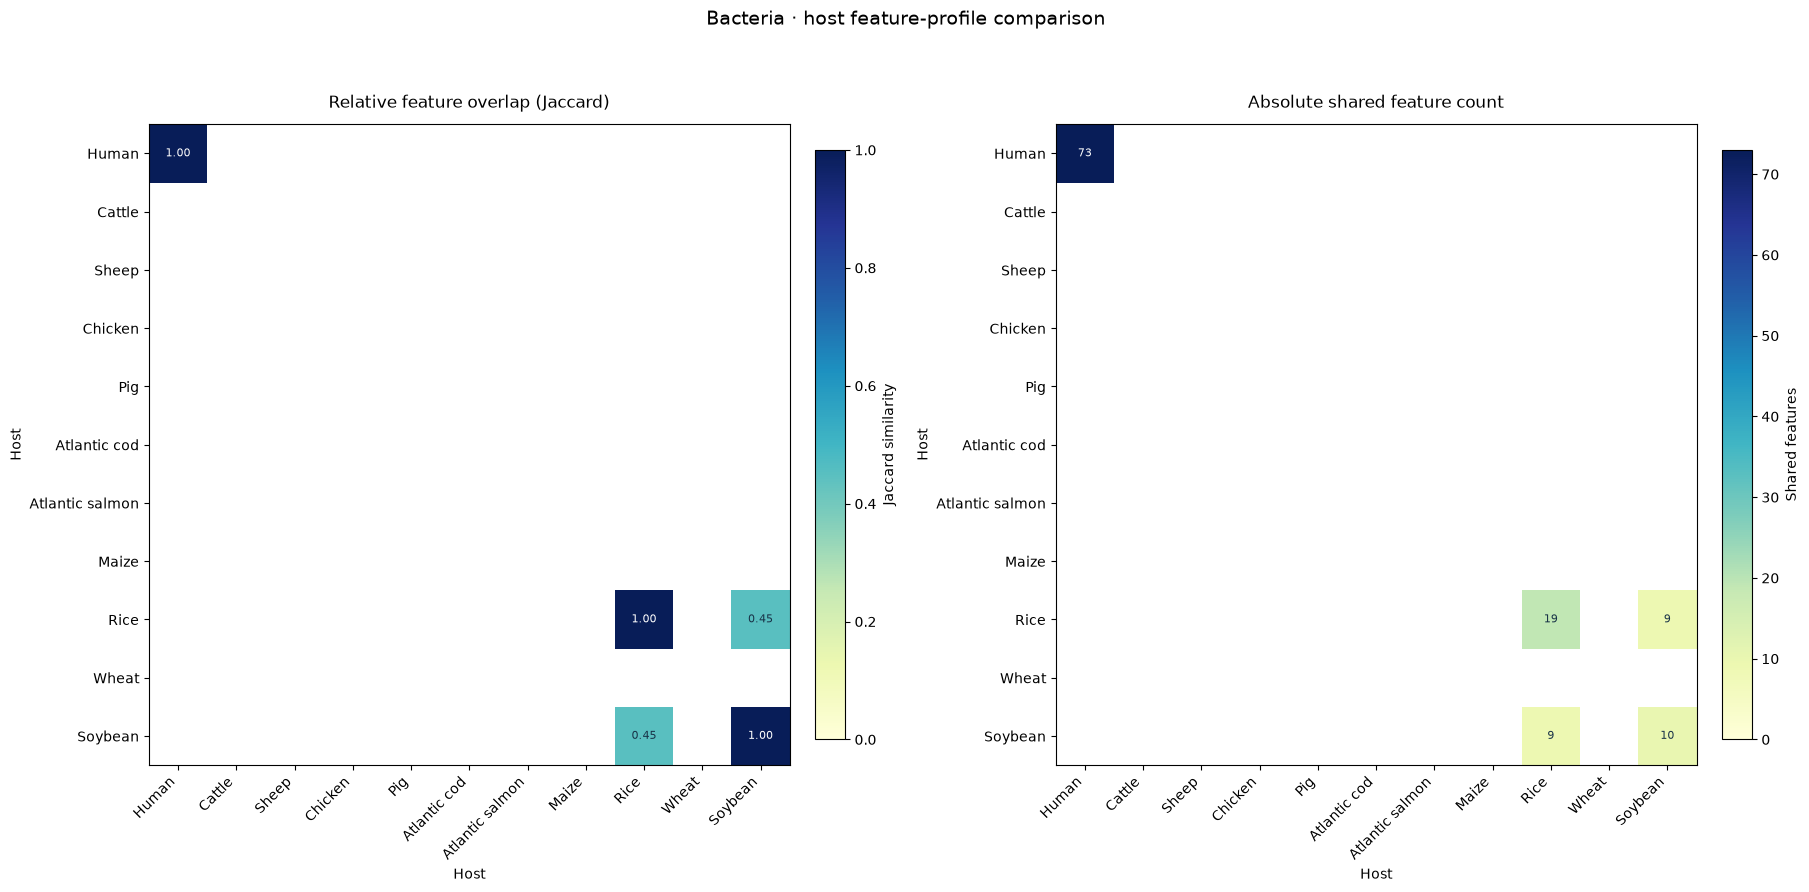

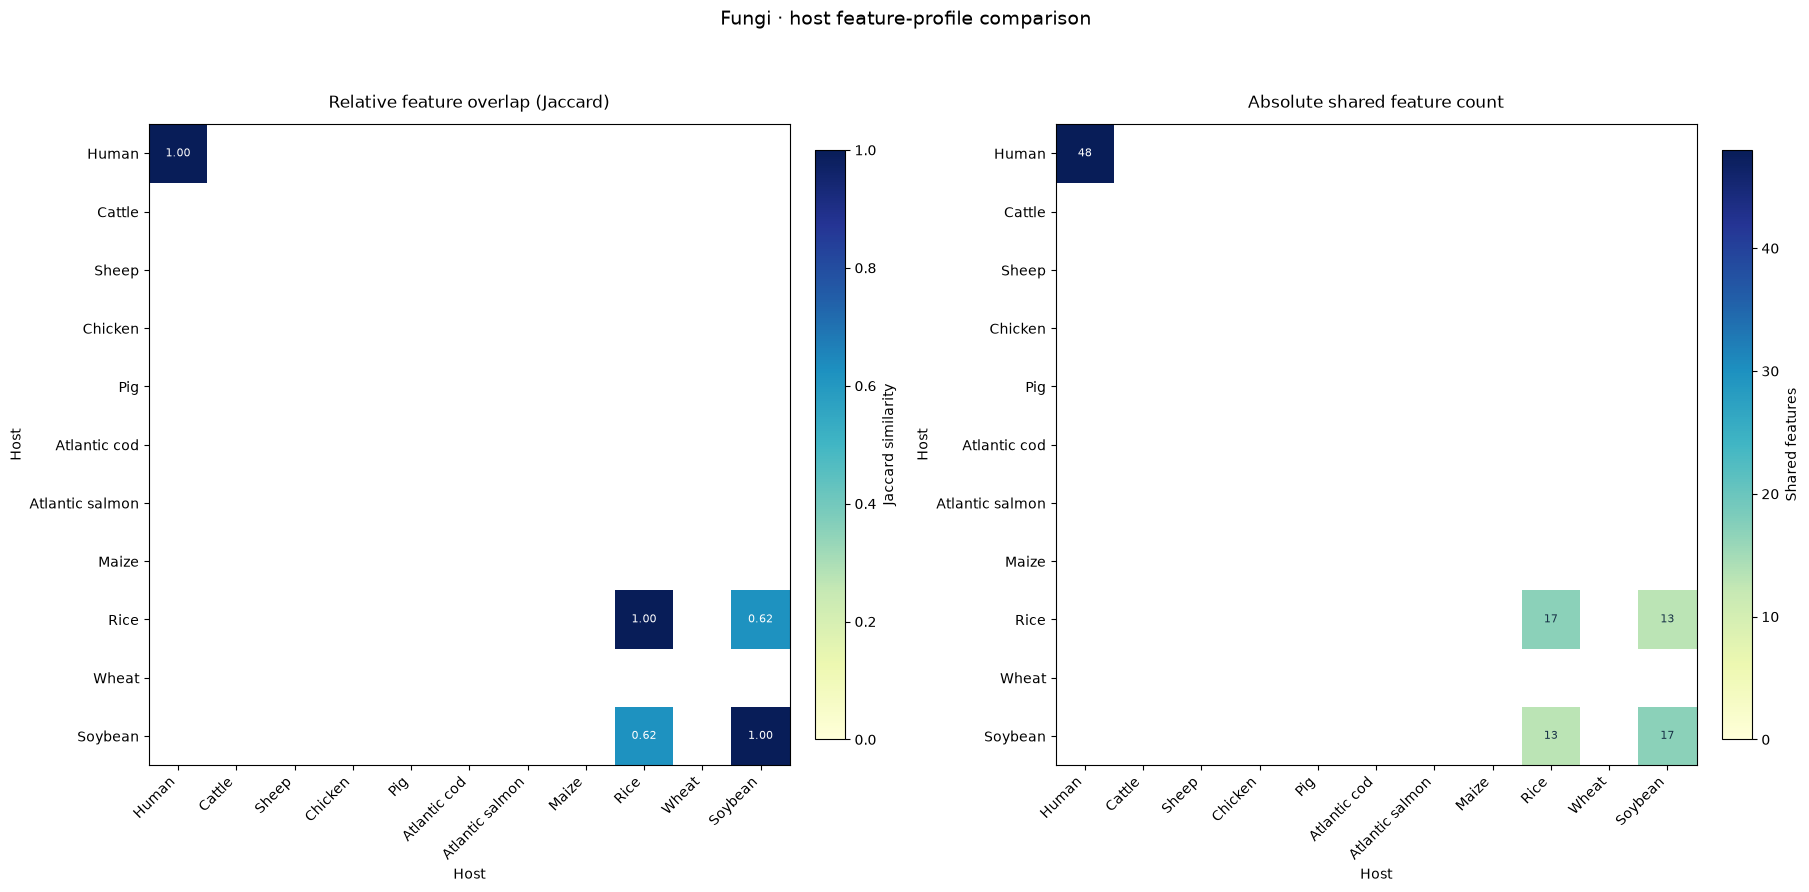

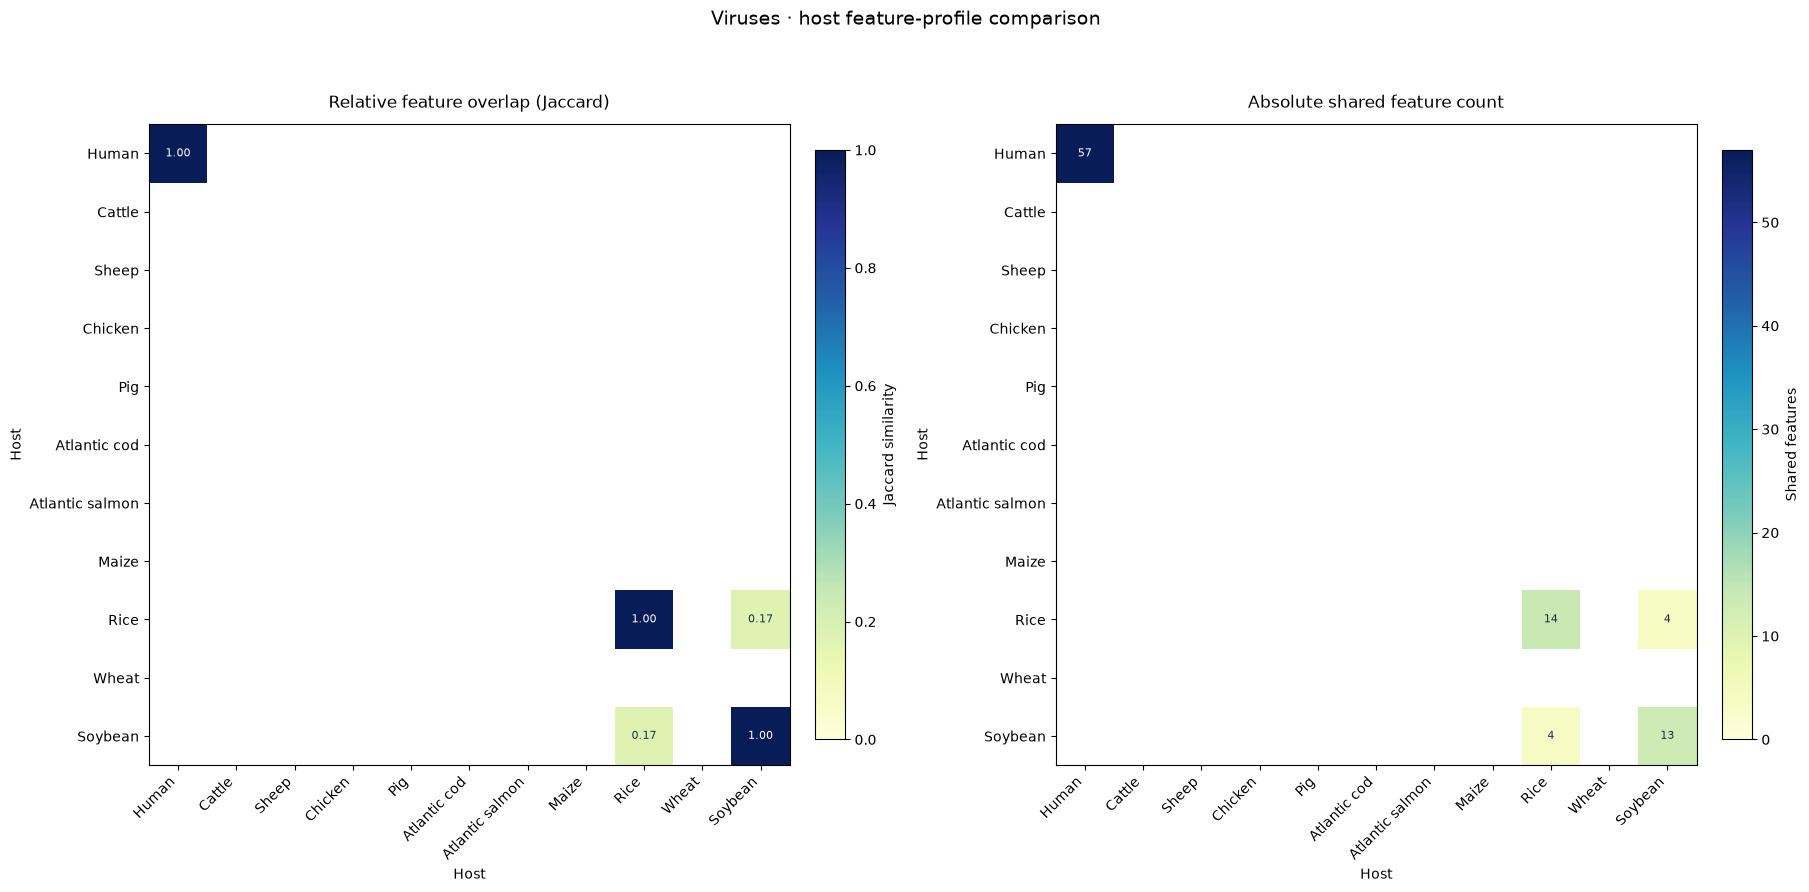

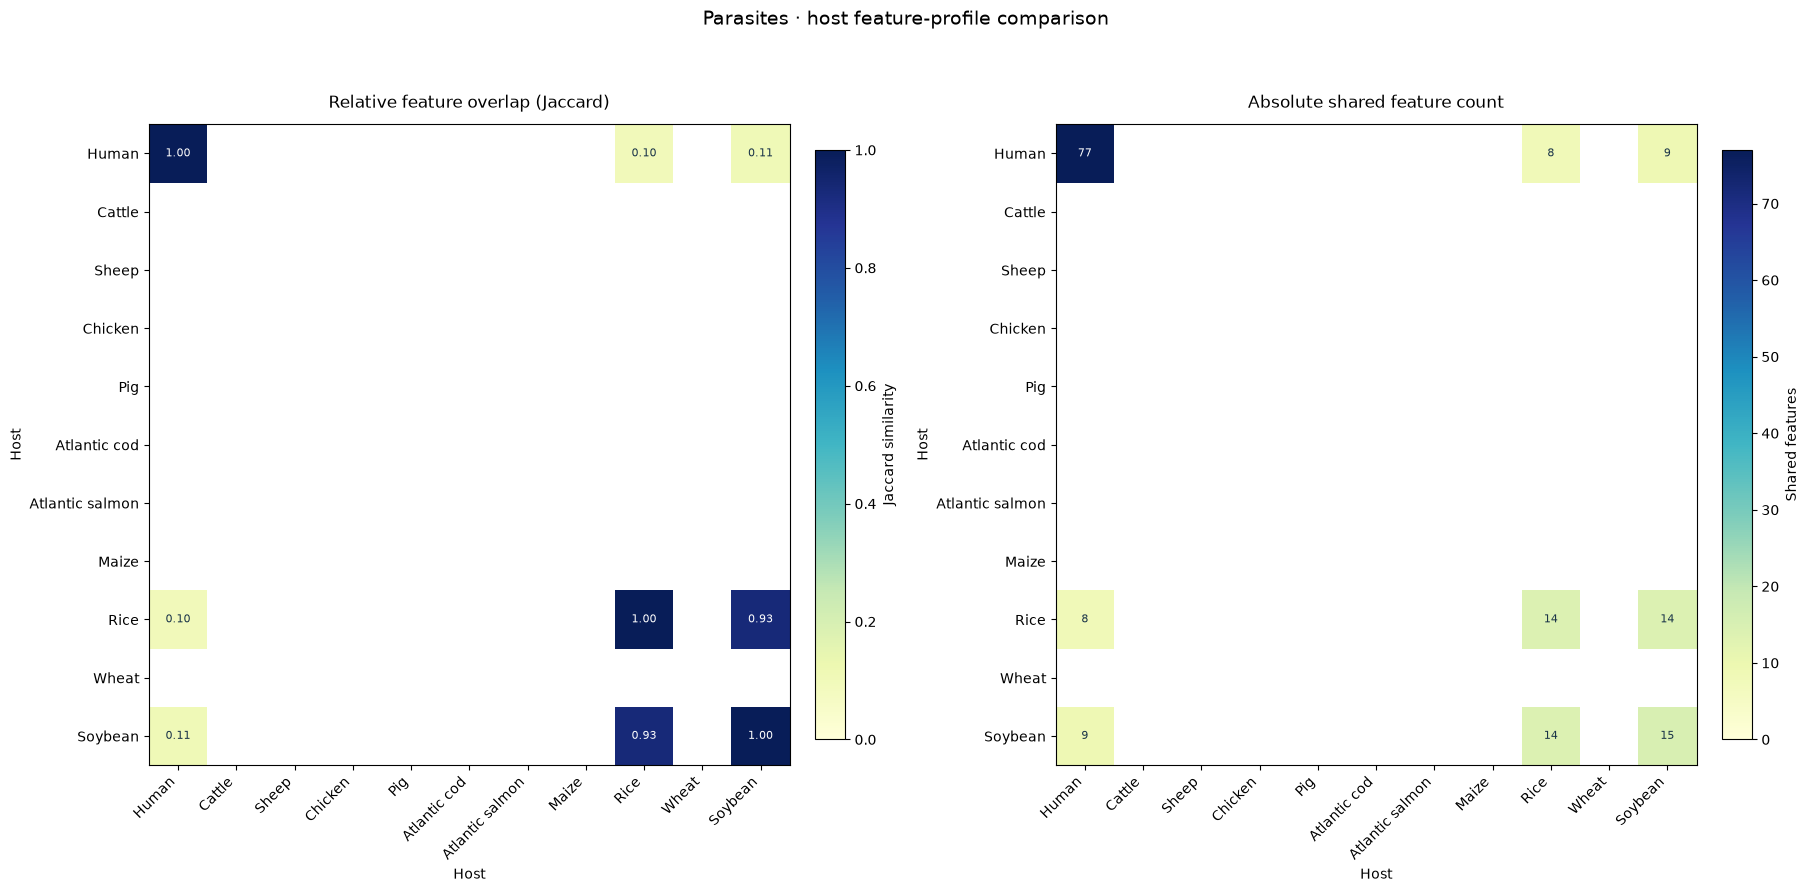

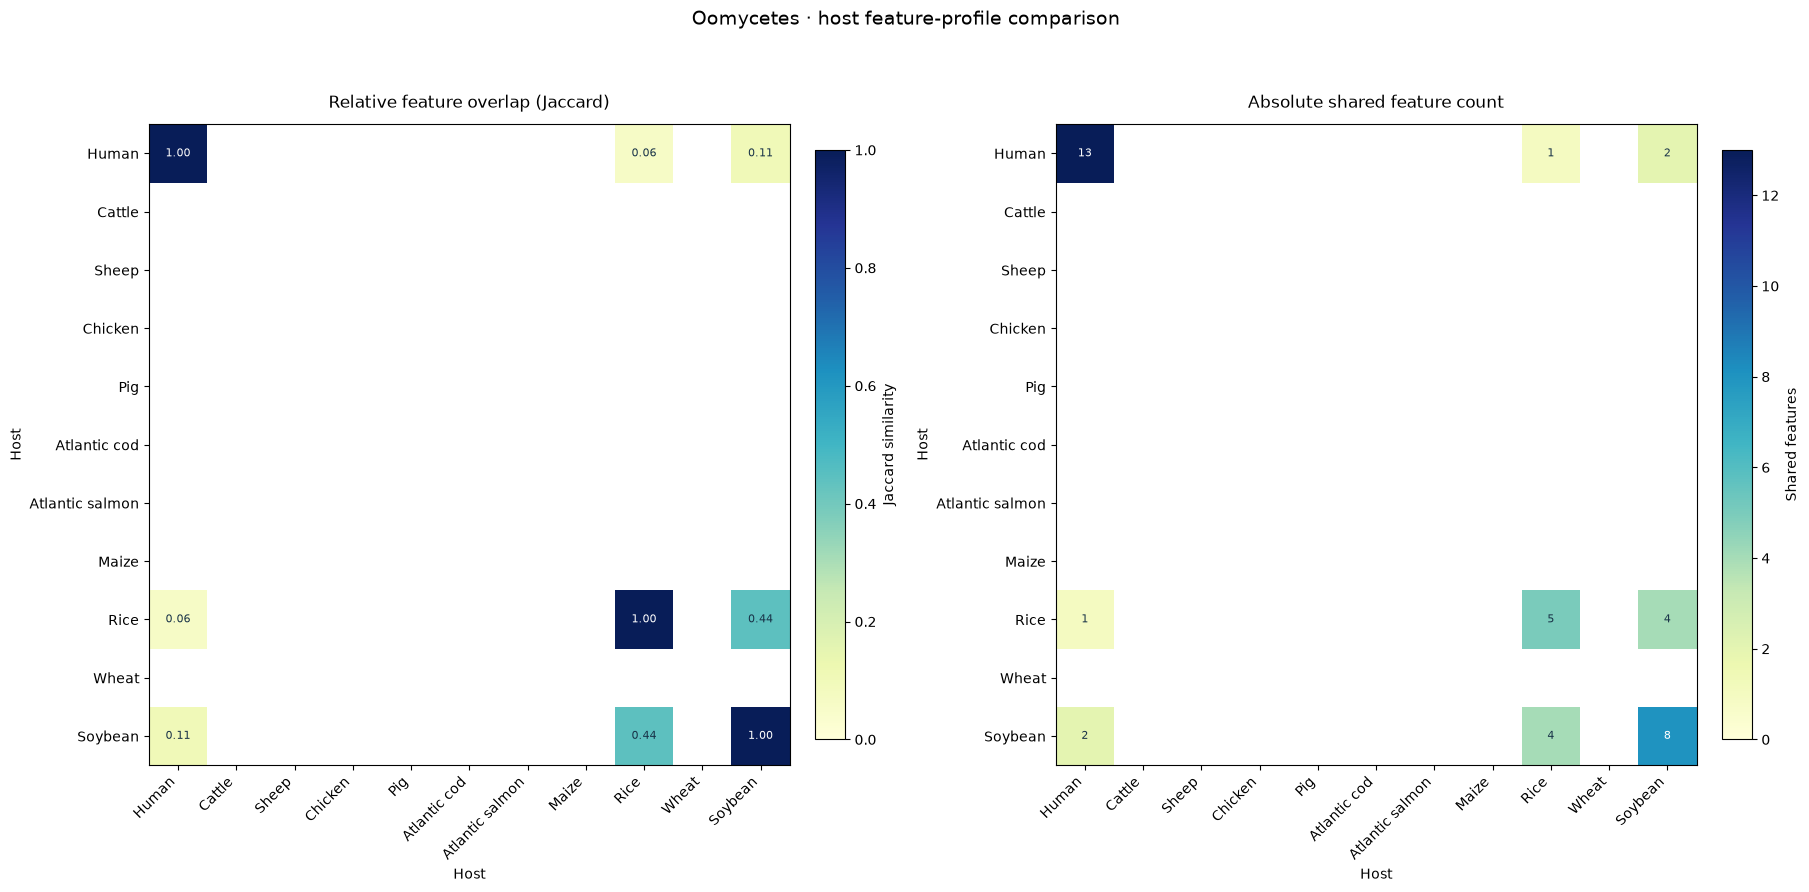

In [4]:
plot_jaccard_matrices(analysis)

## 3 · Pairwise overlap details

The table exposes the shared-feature count and union size behind each matrix score.

In [5]:
display(
    analysis["pairwise_comparisons"]
    .sort_values(["pathogen_group", "jaccard", "host_a", "host_b"], ascending=[True, False, True, True])
    .reset_index(drop=True)
)

,pathogen_group,host_a,host_b,features_a,features_b,intersection,union,jaccard,shared_feature_ids
0,bacteria,Rice,Soybean,19,10,9,20,0.45,abstract_reports_disease; bacterial_toxin_host...
1,bacteria,Atlantic cod,Rice,0,19,0,19,0.00,
2,bacteria,Atlantic cod,Soybean,0,10,0,10,0.00,
3,bacteria,Atlantic salmon,Rice,0,19,0,19,0.00,
4,bacteria,Atlantic salmon,Soybean,0,10,0,10,0.00,
...,...,...,...,...,...,...,...,...,...
270,viruses,Sheep,Atlantic salmon,0,0,0,0,NaN,
271,viruses,Sheep,Chicken,0,0,0,0,NaN,
272,viruses,Sheep,Maize,0,0,0,0,NaN,
273,viruses,Sheep,Pig,0,0,0,0,NaN,


## 4 · Compare two hosts in one shared-feature space

The map uses the intersection of the selected hosts’ resolved feature identities. Each dot is a pathogen; each shared feature is an input column. A top legend maps the first host to circles and the second to diamonds. Point size follows publication volume score (0–1), and color uses the reversed YlGnBu scale for pathogenicity fraction. A pathogen is included when either host has a confirmed association and scored values for the shared features. Missing feature values are never replaced by zero. The map reports how many confirmed pathogens have the feature scores needed to plot. Hover points to inspect each host’s association status and supporting PMID counts.

In [6]:
display(create_interactive_host_comparison(PROJECT_ROOT, scope_filter=SCOPE_FILTER))